In [2]:
# Importação de bibliotecas para manipulação de dados e visualização
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importação de ferramentas de Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [3]:
# Carregar o dataset real de phishing (ajusta o caminho se o teu CSV estiver noutra pasta)
df = pd.read_csv('../data/phishing_emails.csv')

# Mostrar as primeiras 5 linhas para garantir que os dados carregaram bem
display(df.head())

# Mostrar estatísticas descritivas (dá um aspeto muito analítico ao trabalho)
display(df.describe())

,email_id,sender_email,subject,has_link,has_attachment,urgency_score,spelling_errors,email_length_words,is_phishing
0,1,harrisonsandra@paypal-alert.com,Meeting Reminder,0,1,2,0,227,0
1,2,randyharris@bankverify.net,Urgent Account Verification,1,1,9,7,59,1
2,3,adam13@outlook.com,Suspicious Login Attempt,1,1,8,10,67,1
3,4,kennethfisher@company-secure.com,Suspicious Login Attempt,0,1,9,8,102,1
4,5,wsandoval@paypal-alert.com,Your Password Will Expire,1,0,7,4,96,1


,email_id,has_link,has_attachment,urgency_score,spelling_errors,email_length_words,is_phishing
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,750.500000,0.629333,0.512667,5.722667,3.708000,132.559333,0.493333
std,433.157015,0.483144,0.500006,3.002182,3.209819,79.315970,0.500122
min,1.000000,0.000000,0.000000,1.000000,0.000000,20.000000,0.000000
25%,375.750000,0.000000,0.000000,3.000000,1.000000,72.000000,0.000000
50%,750.500000,1.000000,1.000000,5.000000,2.000000,108.000000,0.000000
75%,1125.250000,1.000000,1.000000,8.000000,6.000000,193.000000,1.000000
max,1500.000000,1.000000,1.000000,10.000000,10.000000,300.000000,1.000000


In [4]:
# Definir as variáveis de entrada (X) e o alvo (y)
# Assumindo que a coluna final se chama 'is_phishing'
X = df[['has_link', 'has_attachment', 'urgency_score', 'spelling_errors', 'email_length_words']]
y = df['is_phishing']

# Dividir os dados: 80% para treinar a IA, 20% para a testar
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Dados de Treino: {X_train.shape[0]} e-mails")
print(f"Dados de Teste: {X_test.shape[0]} e-mails")

Dados de Treino: 1200 e-mails
Dados de Teste: 300 e-mails


In [1]:
# Inicializar o algoritmo Random Forest com 100 árvores de decisão
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Treinar o modelo com os dados de treino
rf_model.fit(X_train, y_train)

print("Modelo Random Forest treinado com sucesso!")

NameError: name 'RandomForestClassifier' is not defined

Precisão do Modelo: 100.00%

Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       145
           1       1.00      1.00      1.00       155

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



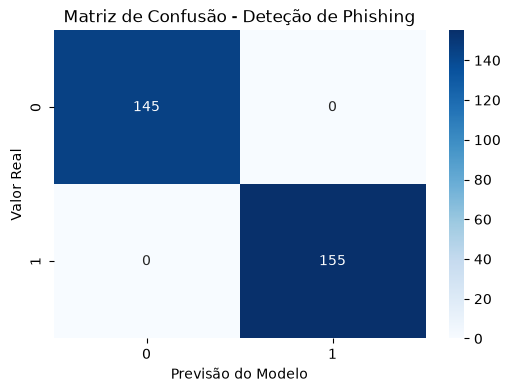

In [ ]:
# Fazer previsões com os dados de teste que o modelo nunca viu
y_pred = rf_model.predict(X_test)

# Calcular a precisão global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisão do Modelo: {accuracy * 100:.2f}%\n")

# Gerar o relatório detalhado
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred))

# Gerar uma Matriz de Confusão visual (Gráfico)
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão - Deteção de Phishing')
plt.xlabel('Previsão do Modelo')
plt.ylabel('Valor Real')
plt.show()

In [ ]:
# Guardar o modelo treinado para ser usado pela API FastAPI no main.py
joblib.dump(rf_model, '../app/random_forest_phishing.pkl')

print("Modelo exportado com sucesso como 'random_forest_phishing.pkl'")

Modelo exportado com sucesso como 'random_forest_phishing.pkl'


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# 1. Modelos candidatos (cobre os modelos do Slide 14 + Gradient Boosting)
modelos = {
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=42),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

resultados = []
melhor_modelo = None
melhor_f1 = -1
nome_melhor = ""
melhores_preds = None

# 2. Treinar e avaliar todos nos mesmos dados de teste (20%)
for nome, clf in modelos.items():
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    probs = clf.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    auc = roc_auc_score(y_test, probs)
    
    resultados.append({
        "Modelo": nome,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2),
        "ROC-AUC (%)": round(auc * 100, 2)
    })
    
    if f1 > melhor_f1:
        melhor_f1 = f1
        melhor_modelo = clf
        nome_melhor = nome
        melhores_preds = preds

# 3. Tabela comparativa ordenada pelo F1-Score
df_comparacao = pd.DataFrame(resultados).sort_values(by="F1-Score (%)", ascending=False)
display(df_comparacao)

# 4. Gráficos: Comparação de F1-Score e Matriz de Confusão do modelo vencedor
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df_comparacao, x="F1-Score (%)", y="Modelo", ax=axes[0], palette="Blues_r")
axes[0].set_title("Comparação de F1-Score por Modelo")
axes[0].set_xlim(0, 100)

cm = confusion_matrix(y_test, melhores_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["Legítimo (0)", "Phishing (1)"],
            yticklabels=["Legítimo (0)", "Phishing (1)"])
axes[1].set_title(f"Matriz de Confusão — {nome_melhor}")
axes[1].set_xlabel("Previsto")
axes[1].set_ylabel("Real")

plt.tight_layout()
plt.show()

In [ ]:
import joblib

# Guardar tabela comparativa em CSV dentro da pasta notebooks/
df_comparacao.to_csv("comparacao_modelos_phishing.csv", index=False)

# Exportar o modelo vencedor para a pasta app/ (mantém o nome esperado pelo main.py)
joblib.dump(melhor_modelo, "../app/random_forest_phishing.pkl")

print(f"✅ Tabela guardada em 'notebooks/comparacao_modelos_phishing.csv'")
print(f"✅ Modelo vencedor ({nome_melhor} | F1: {melhor_f1*100:.2f}%) exportado para 'app/random_forest_phishing.pkl'")